# Support Vector Regression — GAT IOP Prediction

This notebook develops a Support Vector Regression (SVR) model to predict Applanation/GAT IOP from:

- iCare IOP
- Central Corneal Thickness (CCT)

It uses the same patient-level train / validation / test splits as the Random Forest, ANN and XGBoost notebooks, and the same evaluation, so all four models can be compared directly.

The test set remains untouched until the final evaluation section.

## What this notebook finds

Stated up front so the experiments below can be read with the destination in mind.

- **Test MAE 2.912 mmHg, RMSE 4.084, R² 0.717.** Between XGBoost (2.901) and Random Forest (2.920) on MAE, and the weakest of the three on RMSE and R².
- **Validation MAE 2.829** — inside the same 0.04 mmHg band as Random Forest (2.806), XGBoost (2.809) and the ANN (2.847). A fourth, unrelated model family lands in the same place.
- **SVR is the best model in the 10–20 mmHg band** (MAE 1.97 against XGBoost's 2.09), and worse than XGBoost at 20–40 mmHg.
- **The fitted curve turns downward above ~58 mmHg iCare.** Higher iCare readings produce *lower* predicted GAT. This is a property of the RBF kernel with sparse data at the top, and it alone rules SVR out for clinical use without a fix.
- **CCT contributes nothing measurable**, as in every other notebook.

### Why SVR after the tree models

SVR is a different family from both Random Forest and XGBoost, which is the point of trying it.

- **Tree ensembles** cut the (iCare, CCT) plane into boxes and predict a constant in each box. Their output is a step function, and outside the training range it goes flat.
- **SVR** fits a *smooth* function. With an RBF kernel it can bend, but it cannot produce steps.
- **SVR's loss is ε-insensitive**: errors smaller than ε cost nothing, and larger errors cost in proportion to their size, not their square. That is close to MAE, the metric this project reports, and it makes SVR less sensitive to outlying eyes than a squared-error model.

If SVR lands in the same place as the trees and the ANN, that is further evidence that the limit is the data and not the algorithm.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import RandomizedSearchCV, GroupKFold
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import loguniform

import sklearn
print("scikit-learn:", sklearn.__version__)

scikit-learn: 1.9.0


## Load Dataset

The same splits produced by `src/split_dataset.py` are used here.

In [2]:
train = pd.read_csv("../data/splits/train.csv")
validation = pd.read_csv("../data/splits/validation.csv")
test = pd.read_csv("../data/splits/test.csv")

print("Train:", train.shape)
print("Validation:", validation.shape)
print("Test:", test.shape)

Train: (4648, 5)
Validation: (1001, 5)
Test: (990, 5)


## Features, Target and Patient Groups

Features and target are the same as the other notebooks.

As in `03_xgboost.ipynb`, the **patient UID** is derived from the EUID (`L00220` → `00220`). It is *not* a model feature; it keeps both eyes of a patient inside the same cross-validation fold.

In [3]:
features = ["icare_iop", "cct"]
target = "applanation_iop"

X_train = train[features]
y_train = train[target]

X_validation = validation[features]
y_validation = validation[target]

X_test = test[features]
y_test = test[target]

# Patient-level grouping for cross-validation (NOT a feature)
train_groups = train["euid"].str[1:]

print("Training rows:", len(X_train))
print("Training patients:", train_groups.nunique())

Training rows: 4648
Training patients: 2536


## Evaluation Helper

Every model is scored with the same three metrics as the other notebooks: MAE (mmHg, the clinically interpretable number), RMSE, and R².

In [4]:
def evaluate(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }


def report(name, y_true, y_pred):
    m = evaluate(y_true, y_pred)
    print(f"{name}")
    print("-" * len(name))
    print(f"MAE:  {m['MAE']:.3f} mmHg")
    print(f"RMSE: {m['RMSE']:.3f} mmHg")
    print(f"R²:   {m['R2']:.3f}")
    return m

## Reference Baselines

The same three baselines as `03_xgboost.ipynb`, recomputed here so this notebook stands on its own:

1. **Identity** — predict GAT = iCare directly.
2. **Linear regression on iCare only.**
3. **Linear regression on iCare + CCT.**

In [5]:
lin_icare = LinearRegression().fit(X_train[["icare_iop"]], y_train)
lin_both = LinearRegression().fit(X_train, y_train)

baseline_df = pd.DataFrame([
    {"Model": "Identity (GAT = iCare)",
     **evaluate(y_validation, X_validation["icare_iop"])},
    {"Model": "Linear (iCare only)",
     **evaluate(y_validation, lin_icare.predict(X_validation[["icare_iop"]]))},
    {"Model": "Linear (iCare + CCT)",
     **evaluate(y_validation, lin_both.predict(X_validation))},
])

print("Validation performance of non-ML baselines")
baseline_df

Validation performance of non-ML baselines


,Model,MAE,RMSE,R2
0,Identity (GAT = iCare),2.996004,4.258270,0.633093
1,Linear (iCare only),2.882584,4.042865,0.669274
2,Linear (iCare + CCT),2.891902,4.042444,0.669343


## Experiment 1: Why Scaling Matters

SVR measures distance between points. The RBF kernel compares two eyes by how far apart they are in feature space, and the regularisation treats every direction the same.

Our two features live on very different scales: iCare IOP is roughly 4–72 mmHg, CCT is 480–580 µm. Without scaling, a 10 µm difference in CCT counts the same as a 10 mmHg difference in pressure, which is clinically absurd. Scaling also changes what the default `gamma="scale"` means.

We fit SVR with default settings, with and without standardisation, to see the size of the effect. `StandardScaler` is placed inside a pipeline so it is fitted on training data only, and refitted inside each cross-validation fold later.

In [6]:
scaling_rows = []

for name, model in [
    ("SVR, raw features", SVR()),
    ("SVR, standardised", make_pipeline(StandardScaler(), SVR())),
]:
    start = time.perf_counter()
    model.fit(X_train, y_train)
    elapsed = time.perf_counter() - start

    scaling_rows.append({
        "Model": name,
        "Fit time (s)": elapsed,
        "Train MAE": mean_absolute_error(y_train, model.predict(X_train)),
        **evaluate(y_validation, model.predict(X_validation)),
    })

scaling_df = pd.DataFrame(scaling_rows)

scaling_df

,Model,Fit time (s),Train MAE,MAE,RMSE,R2
0,"SVR, raw features",0.465814,3.931788,3.870489,6.012122,0.268616
1,"SVR, standardised",0.458377,2.849242,2.855154,4.151536,0.651255


### What happened

Unscaled SVR scores validation MAE **3.870** and R² 0.27 — far worse than simply reading the iCare number (2.996). Standardising the same model gives **2.855**.

Nothing else changed. On raw features, CCT's spread (tens of µm) dominates the RBF distance, so the kernel mostly compares eyes by corneal thickness, the feature that turns out to carry no signal. Every SVR from here on is a `StandardScaler → SVR` pipeline.

## Experiment 2: Kernel Choice

The kernel decides what shape of function SVR can fit:

- **linear** — a plane. Equivalent in shape to the linear baselines, but fitted with the ε-insensitive loss instead of squared error.
- **poly (degree 2, 3)** — a quadratic or cubic surface.
- **rbf** — a smooth, flexible surface built from bumps around training points.

All use default `C=1`, `epsilon=0.1`, on standardised features.

In [7]:
kernel_configs = [
    ("linear", {"kernel": "linear"}),
    ("poly, degree 2", {"kernel": "poly", "degree": 2}),
    ("poly, degree 3", {"kernel": "poly", "degree": 3}),
    ("rbf", {"kernel": "rbf"}),
]

kernel_rows = []

for name, params in kernel_configs:
    model = make_pipeline(StandardScaler(), SVR(**params))
    model.fit(X_train, y_train)

    kernel_rows.append({
        "Kernel": name,
        "Support vectors": len(model[-1].support_),
        **evaluate(y_validation, model.predict(X_validation)),
    })

kernel_df = pd.DataFrame(kernel_rows)

kernel_df

,Kernel,Support vectors,MAE,RMSE,R2
0,linear,4532,2.856250,4.090539,0.661428
1,"poly, degree 2",4614,4.261131,5.871804,0.302357
2,"poly, degree 3",4569,3.781041,6.109945,0.244622
3,rbf,4536,2.855154,4.151536,0.651255


### What happened

**Linear and RBF tie** (2.856 and 2.855). The polynomial kernels look terrible (4.26 and 3.78), but that is a parameter artefact rather than a verdict on curvature: with scikit-learn's default `coef0=0`, a degree-2 kernel contains only squared terms and a degree-3 kernel only cubic ones — neither can represent a straight line, which is the dominant pattern here. RBF can bend *and* represent the line, so it is carried forward.

One side result is worth keeping. The linear-kernel SVR scores **2.856 against ordinary least squares' 2.883** with the same straight-line shape. That 0.03 mmHg comes entirely from the loss function: SVR's ε-insensitive loss grows linearly with error instead of quadratically, so a few wildly discordant eyes pull the line less.

## Experiment 3: Regularisation Strength C

`C` sets how heavily SVR penalises points that fall outside the ε-tube. Small `C` gives a flatter, more regularised function; large `C` lets the function chase individual eyes.

We sweep `C` over five orders of magnitude with the RBF kernel.

In [8]:
C_values = [0.01, 0.1, 1, 3, 10, 30, 100, 1000]

C_rows = []

for C in C_values:
    model = make_pipeline(StandardScaler(), SVR(kernel="rbf", C=C))
    model.fit(X_train, y_train)

    C_rows.append({
        "C": C,
        "Support vectors": len(model[-1].support_),
        "Train MAE": mean_absolute_error(y_train, model.predict(X_train)),
        **evaluate(y_validation, model.predict(X_validation)),
    })

C_df = pd.DataFrame(C_rows)

C_df

,C,Support vectors,Train MAE,MAE,RMSE,R2
0,0.01,4528,3.857099,3.751289,6.193422,0.223840
1,0.10,4547,3.222677,3.082131,4.910294,0.512129
2,1.00,4536,2.849242,2.855154,4.151536,0.651255
3,3.00,4547,2.778886,2.851881,4.119927,0.656546
4,10.00,4531,2.758274,2.848609,4.104161,0.659169
5,30.00,4530,2.745875,2.858603,4.104299,0.659146
6,100.00,4531,2.736090,2.865855,4.110728,0.658078
7,1000.00,4518,2.725488,2.890732,4.168926,0.648327


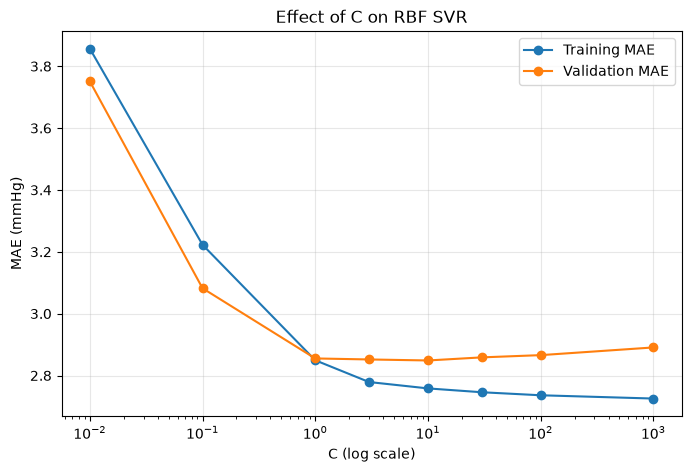

In [9]:
plt.figure(figsize=(8, 5))

plt.semilogx(C_df["C"], C_df["Train MAE"], marker="o", label="Training MAE")
plt.semilogx(C_df["C"], C_df["MAE"], marker="o", label="Validation MAE")

plt.xlabel("C (log scale)")
plt.ylabel("MAE (mmHg)")
plt.title("Effect of C on RBF SVR")

plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### What happened

Too little `C` is badly underfitted (3.75 at C=0.01). From **C=1 to C=100 validation MAE barely moves** — 2.849 to 2.866 — with the best at C=10.

The training curve keeps falling as C grows (2.849 → 2.725) while validation turns upward after C=10. That is the familiar overfitting pattern, but mild: even C=1000 only costs about 0.04 mmHg. As with tree depth in the XGBoost notebook, once there is enough capacity to fit a gently curved line, there is little more to find.

## Experiment 4: Tube Width ε

`epsilon` is the half-width of the tube inside which errors cost nothing. A wider tube ignores more small errors and uses fewer support vectors; a narrower tube makes every eye count.

For context, GAT is read to roughly the nearest 0.5–1 mmHg, so errors below that are measurement noise.

In [10]:
epsilon_values = [0.0, 0.1, 0.25, 0.5, 1.0, 2.0, 3.0]

epsilon_rows = []

for eps in epsilon_values:
    model = make_pipeline(StandardScaler(), SVR(kernel="rbf", C=1, epsilon=eps))
    model.fit(X_train, y_train)

    epsilon_rows.append({
        "epsilon": eps,
        "Support vectors": len(model[-1].support_),
        **evaluate(y_validation, model.predict(X_validation)),
    })

epsilon_df = pd.DataFrame(epsilon_rows)

epsilon_df

,epsilon,Support vectors,MAE,RMSE,R2
0,0.00,4648,2.854828,4.153393,0.650943
1,0.10,4536,2.855154,4.151536,0.651255
2,0.25,4363,2.852337,4.147335,0.651961
3,0.50,4028,2.851048,4.145660,0.652242
4,1.00,3482,2.856118,4.146310,0.652133
5,2.00,2447,2.856335,4.133441,0.654289
6,3.00,1671,2.871271,4.124538,0.655776


### What happened

Validation MAE is flat across ε — **2.851 to 2.871 from ε=0 to ε=3**.

What changes is the number of support vectors, which falls from all 4,648 eyes at ε=0 to 1,671 at ε=3. A 3 mmHg tube ignores more than half the training eyes and loses almost nothing. Most eyes sit within a few mmHg of a smooth curve, and the eyes that define the fit are the ones that don't.

## Experiment 5: Randomised Search with Patient-Grouped Cross-Validation

The sweeps above change one setting at a time. We now search `C`, `gamma` and `epsilon` jointly: 60 random configurations, each scored by 5-fold `GroupKFold` cross-validation on patient UID — the same scheme as `03_xgboost.ipynb`, so the CV scores are comparable.

`C` and `gamma` are drawn on a log scale, because their effect is multiplicative. The scaler lives inside the pipeline, so each fold is standardised using only its own training portion.

In [11]:
param_distributions = {
    "svr__C": loguniform(0.01, 1000),
    "svr__gamma": loguniform(0.001, 10),
    "svr__epsilon": [0.0, 0.1, 0.25, 0.5, 1.0, 1.5, 2.0],
}

search = RandomizedSearchCV(
    estimator=make_pipeline(StandardScaler(), SVR(kernel="rbf", cache_size=1000)),
    param_distributions=param_distributions,
    n_iter=60,
    scoring="neg_mean_absolute_error",
    cv=GroupKFold(n_splits=5),
    random_state=42,
    n_jobs=-1,
    verbose=1,
)

search.fit(X_train, y_train, groups=train_groups)

Fitting 5 folds for each of 60 candidates, totalling 300 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._size=1000))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'svr__C': <scipy.stats....x79b9c54473e0>, 'svr__epsilon': [0.0, 0.1, ...], 'svr__gamma': <scipy.stats....x79b9c9ec6cf0>}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",60
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",GroupKFold(n_...shuffle=False)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`

In [12]:
print("Best parameters:")
for key, value in sorted(search.best_params_.items()):
    print(f"  {key}: {value:.4g}")

print(f"\nBest patient-grouped cross-validation MAE: {-search.best_score_:.4f}")

Best parameters:
  svr__C: 15.41
  svr__epsilon: 0.25
  svr__gamma: 0.1758

Best patient-grouped cross-validation MAE: 2.7967


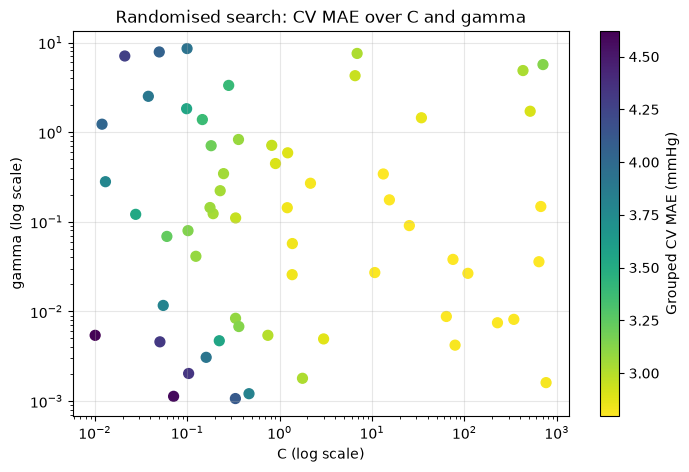

In [13]:
search_results = pd.DataFrame(search.cv_results_)

plt.figure(figsize=(8, 5))

points = plt.scatter(
    search_results["param_svr__C"].astype(float),
    search_results["param_svr__gamma"].astype(float),
    c=-search_results["mean_test_score"],
    cmap="viridis_r",
    s=50,
)

plt.xscale("log")
plt.yscale("log")
plt.colorbar(points, label="Grouped CV MAE (mmHg)")
plt.xlabel("C (log scale)")
plt.ylabel("gamma (log scale)")
plt.title("Randomised search: CV MAE over C and gamma")

plt.grid(True, alpha=0.3)
plt.show()

In [14]:
best_svr = search.best_estimator_

search_metrics = report(
    "Tuned SVR — Validation",
    y_validation,
    best_svr.predict(X_validation),
)

Tuned SVR — Validation
----------------------
MAE:  2.829 mmHg
RMSE: 4.060 mmHg
R²:   0.666


### What the search chose

`C ≈ 15`, `gamma ≈ 0.18`, `epsilon = 0.25`, patient-grouped CV MAE **2.797**, validation MAE **2.829**.

The scatter shows a broad yellow plateau: almost any configuration with C above ~1 scores within a few hundredths of the best. Only very small C, or very large gamma combined with small C, does clearly worse. As in the XGBoost notebook, the search confirms the plateau the one-at-a-time sweeps had already found.

The grouped CV MAE (2.797) is lower than XGBoost's (2.838), but the validation MAE is higher (2.829 against 2.809). The validation set is the like-for-like comparison; the CV gap is within the noise of a 5-fold estimate.

## Final SVR Model

We fix the configuration selected by the search and refit it on the full training set, so the rest of the notebook works with a single, explicitly specified model.

In [15]:
final_params = {k.replace("svr__", ""): v for k, v in search.best_params_.items()}

final_svr = make_pipeline(
    StandardScaler(),
    SVR(kernel="rbf", cache_size=1000, **final_params),
)

final_svr.fit(X_train, y_train)

train_predictions = final_svr.predict(X_train)
validation_predictions = final_svr.predict(X_validation)

print("Support vectors:", len(final_svr[-1].support_), "of", len(X_train))
final_params

Support vectors: 4359 of 4648


{'C': np.float64(15.409457762881532),
 'epsilon': 0.25,
 'gamma': np.float64(0.17578171745893567)}

## Overfitting Check

A small gap between training and validation MAE means the model generalises to unseen patients.

In [16]:
train_metrics = report("Training", y_train, train_predictions)
print()
validation_metrics = report("Validation", y_validation, validation_predictions)

print(f"\nMAE gap (validation - training): "
      f"{validation_metrics['MAE'] - train_metrics['MAE']:+.3f} mmHg")

Training
--------
MAE:  2.772 mmHg
RMSE: 3.847 mmHg
R²:   0.714

Validation
----------
MAE:  2.829 mmHg
RMSE: 4.060 mmHg
R²:   0.666

MAE gap (validation - training): +0.058 mmHg


### What happened

Training MAE 2.772, validation MAE 2.829 — a gap of **0.058 mmHg**, slightly larger than XGBoost's 0.022 but still small.

The model is not memorising patients. As with the other models, the limiting factor is not overfitting.

## The Fitted Curve

With two inputs, and CCT contributing little, we can look at the model directly: hold CCT at its training median and plot predicted GAT against iCare, alongside the straight-line baseline.

This is the one view a tree model cannot give cleanly, and it shows what SVR does at the edges of the data.

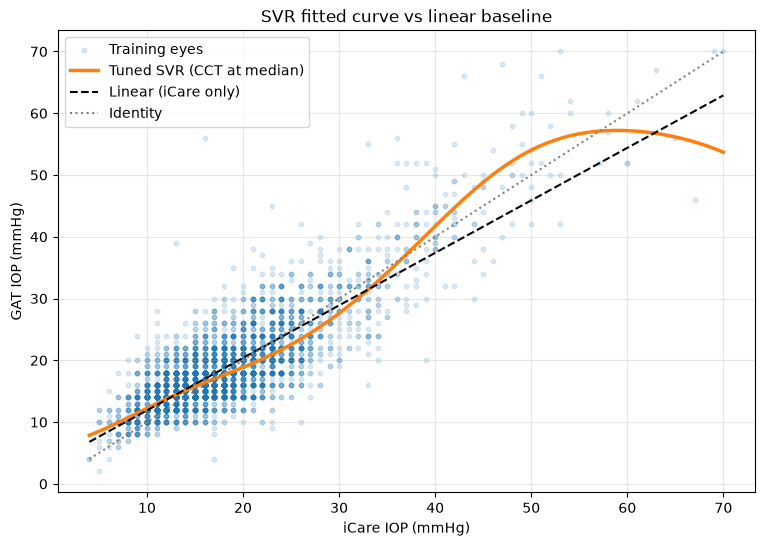

Training eyes with iCare >= 30: 5.8%
Training eyes with iCare >= 40: 85


In [17]:
icare_grid = np.linspace(X_train["icare_iop"].min(), X_train["icare_iop"].max(), 300)
grid = pd.DataFrame({
    "icare_iop": icare_grid,
    "cct": X_train["cct"].median(),
})

plt.figure(figsize=(9, 6))

plt.scatter(X_train["icare_iop"], y_train, alpha=0.15, s=10, label="Training eyes")
plt.plot(icare_grid, final_svr.predict(grid), color="C1", linewidth=2.5,
         label="Tuned SVR (CCT at median)")
plt.plot(icare_grid, lin_icare.predict(grid[["icare_iop"]]), color="black",
         linestyle="--", label="Linear (iCare only)")
plt.plot(icare_grid, icare_grid, color="grey", linestyle=":", label="Identity")

plt.xlabel("iCare IOP (mmHg)")
plt.ylabel("GAT IOP (mmHg)")
plt.title("SVR fitted curve vs linear baseline")

plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"Training eyes with iCare >= 30: {(X_train['icare_iop'] >= 30).mean() * 100:.1f}%")
print(f"Training eyes with iCare >= 40: {(X_train['icare_iop'] >= 40).sum()}")

### What the curve shows

This is the most important plot in the notebook.

**From 10 to 30 mmHg** the SVR curve follows the straight line closely, sitting slightly below it in the 20–30 range.

**From 35 to 55 mmHg** it rises *above* the line, toward the identity, which the sparse high-pressure eyes suggest is roughly right.

**Above about 58 mmHg it turns down.** At an iCare reading of 70 the model predicts about 54 mmHg — lower than its prediction at 58. Only 5.8% of training eyes have iCare ≥ 30 and just 85 have iCare ≥ 40. Beyond the last dense cluster of data, the RBF kernel's influence fades and the prediction drifts back toward the average.

That behaviour is **clinically unacceptable regardless of the error metrics**: a model whose estimate falls as the measured pressure rises cannot be trusted at the top of the range, where the decisions matter most. The tree models go flat at the edges instead, which is wrong but not backwards. A linear kernel, a monotonic constraint, or clipping to the linear model above the data would all remove it.

## Residual Analysis

Residual = Actual GAT IOP − Predicted GAT IOP. Structure in the residuals means the model is systematically wrong somewhere in the range.

In [18]:
residuals = y_validation - validation_predictions

print("Mean residual:    ", round(residuals.mean(), 4))
print("Median residual:  ", round(residuals.median(), 4))
print("Std of residuals: ", round(residuals.std(), 4))
print("Minimum residual: ", round(residuals.min(), 4))
print("Maximum residual: ", round(residuals.max(), 4))

Mean residual:     0.5853
Median residual:   0.2354
Std of residuals:  4.0199
Minimum residual:  -18.8367
Maximum residual:  23.3908


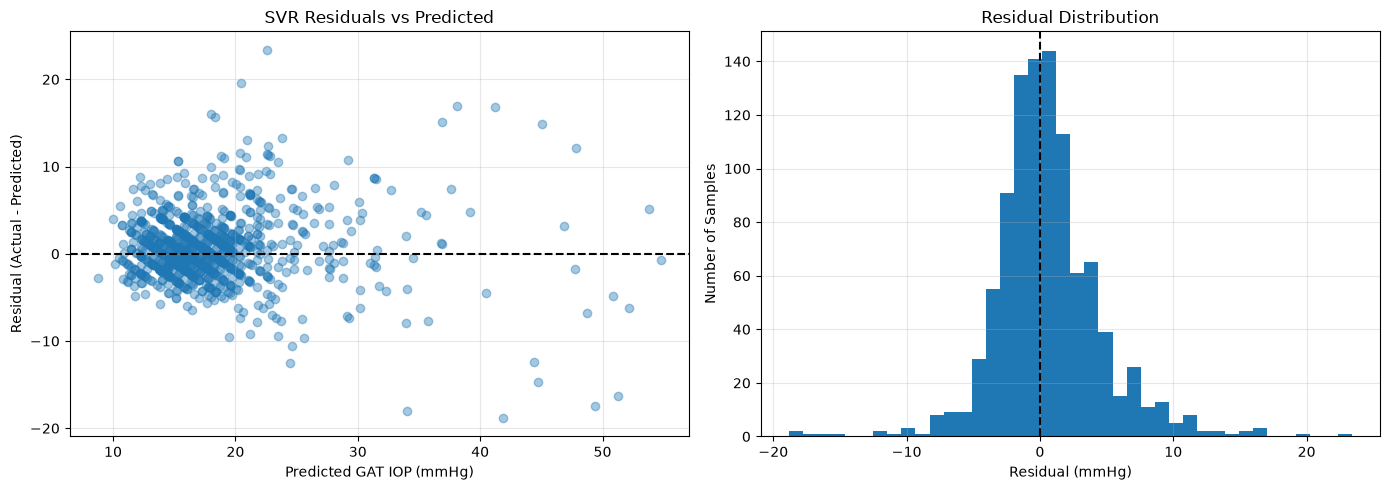

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(validation_predictions, residuals, alpha=0.4)
axes[0].axhline(0, linestyle="--", color="black")
axes[0].set_xlabel("Predicted GAT IOP (mmHg)")
axes[0].set_ylabel("Residual (Actual - Predicted)")
axes[0].set_title("SVR Residuals vs Predicted")
axes[0].grid(True, alpha=0.3)

axes[1].hist(residuals, bins=40)
axes[1].axvline(0, linestyle="--", color="black")
axes[1].set_xlabel("Residual (mmHg)")
axes[1].set_ylabel("Number of Samples")
axes[1].set_title("Residual Distribution")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### What the residuals show

Mean residual **+0.585 mmHg** (median +0.235): SVR under-predicts slightly on average, more than XGBoost (+0.156). The histogram is centred close to zero, with a longer right tail.

The scatter has the same fan shape as the tree models — tight at low predicted pressures, wide at high ones — so errors still grow with pressure. The largest residuals are −18.8 and +23.4 mmHg.

## Actual vs Predicted GAT IOP

A perfect model places every point on the 45° line.

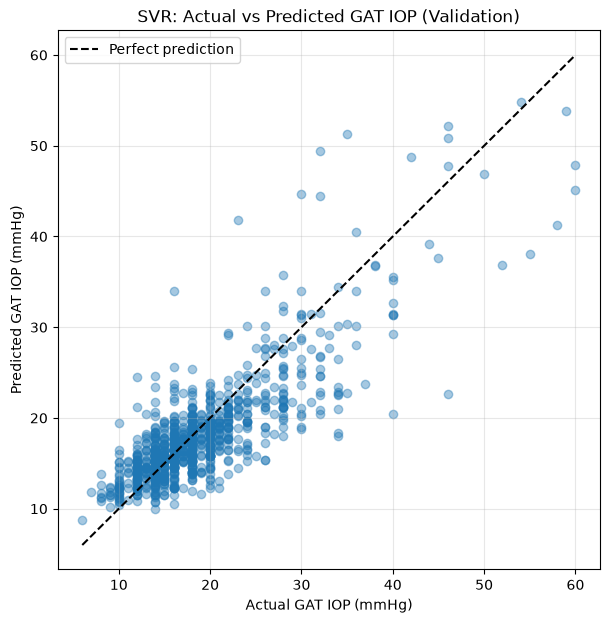

In [20]:
plt.figure(figsize=(7, 7))

plt.scatter(y_validation, validation_predictions, alpha=0.4)

min_iop = min(y_validation.min(), validation_predictions.min())
max_iop = max(y_validation.max(), validation_predictions.max())

plt.plot(
    [min_iop, max_iop],
    [min_iop, max_iop],
    linestyle="--",
    color="black",
    label="Perfect prediction",
)

plt.xlabel("Actual GAT IOP (mmHg)")
plt.ylabel("Predicted GAT IOP (mmHg)")
plt.title("SVR: Actual vs Predicted GAT IOP (Validation)")

plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Bland–Altman Analysis

Bias is the mean difference between actual and predicted GAT; the limits of agreement (bias ± 1.96 × SD) bracket roughly 95% of individual disagreements.

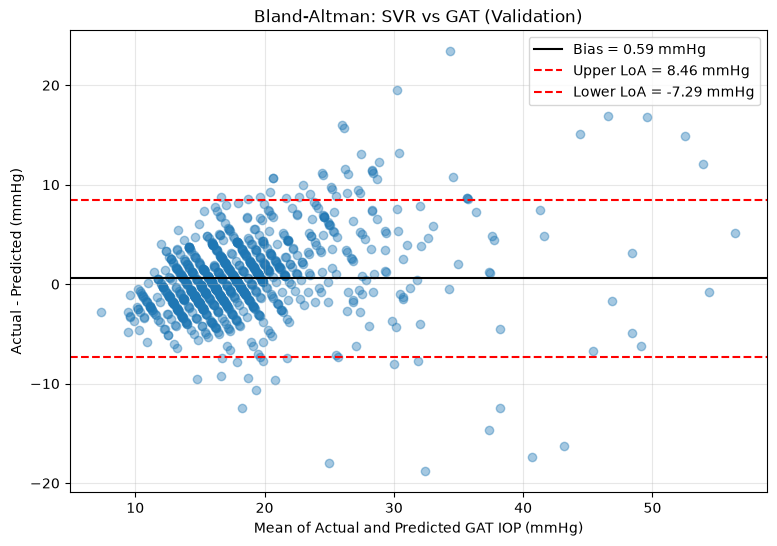

Bias:                  0.585 mmHg
Limits of agreement:   -7.294 to 8.464 mmHg
Within +/- 2 mmHg:     50.9% of eyes
Within +/- 3 mmHg:     66.7% of eyes
Within +/- 5 mmHg:     85.7% of eyes


In [21]:
mean_values = (y_validation + validation_predictions) / 2
differences = y_validation - validation_predictions

bias = differences.mean()
sd = differences.std()

upper_limit = bias + 1.96 * sd
lower_limit = bias - 1.96 * sd

plt.figure(figsize=(9, 6))

plt.scatter(mean_values, differences, alpha=0.4)

plt.axhline(bias, color="black",
            label=f"Bias = {bias:.2f} mmHg")
plt.axhline(upper_limit, color="red", linestyle="--",
            label=f"Upper LoA = {upper_limit:.2f} mmHg")
plt.axhline(lower_limit, color="red", linestyle="--",
            label=f"Lower LoA = {lower_limit:.2f} mmHg")

plt.xlabel("Mean of Actual and Predicted GAT IOP (mmHg)")
plt.ylabel("Actual - Predicted (mmHg)")
plt.title("Bland-Altman: SVR vs GAT (Validation)")

plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"Bias:                  {bias:.3f} mmHg")
print(f"Limits of agreement:   {lower_limit:.3f} to {upper_limit:.3f} mmHg")
print(f"Within +/- 2 mmHg:     "
      f"{(differences.abs() <= 2).mean() * 100:.1f}% of eyes")
print(f"Within +/- 3 mmHg:     "
      f"{(differences.abs() <= 3).mean() * 100:.1f}% of eyes")
print(f"Within +/- 5 mmHg:     "
      f"{(differences.abs() <= 5).mean() * 100:.1f}% of eyes")

### What this means clinically

**Bias +0.59 mmHg, limits of agreement −7.29 to +8.46 mmHg.** The limits are essentially those of XGBoost (−7.70 to +8.01) shifted upward by the larger bias.

**50.9% of eyes within ±2 mmHg, 66.7% within ±3, 85.7% within ±5** — slightly more eyes within ±2 than XGBoost (48.9%), and about the same at ±5. SVR gets more eyes very close, which is the ε-insensitive loss at work: it concentrates on the dense middle of the data.

## Error by IOP Range

The same breakdown as `03_xgboost.ipynb`, with the identity baseline alongside so each band has a reference.

In [22]:
iop_ranges = [
    ("<10", y_validation < 10),
    ("10-20", (y_validation >= 10) & (y_validation < 20)),
    ("20-30", (y_validation >= 20) & (y_validation < 30)),
    ("30-40", (y_validation >= 30) & (y_validation < 40)),
    ("40+", y_validation >= 40),
]

range_results = []

for name, mask in iop_ranges:

    if mask.sum() == 0:
        continue

    actual = y_validation[mask]
    predicted = validation_predictions[mask]
    icare_raw = X_validation.loc[mask, "icare_iop"]

    range_results.append({
        "IOP Range": name,
        "Samples": int(mask.sum()),
        "SVR MAE": mean_absolute_error(actual, predicted),
        "SVR RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "Identity MAE": mean_absolute_error(actual, icare_raw),
        "Mean Residual": (actual - predicted).mean(),
    })

range_results_df = pd.DataFrame(range_results)

xgb_range = pd.read_csv("../results/metrics/xgboost_error_by_iop_range.csv")
range_results_df["XGB MAE (from 03)"] = range_results_df["IOP Range"].map(
    xgb_range.set_index("IOP Range")["XGB MAE"]
)

range_results_df

,IOP Range,Samples,SVR MAE,SVR RMSE,Identity MAE,Mean Residual,XGB MAE (from 03)
0,<10,15,3.258702,3.441648,1.000000,-3.258702,3.728006
1,10-20,641,1.970938,2.672422,2.457098,-0.713609,2.090146
2,20-30,267,3.402709,4.279617,3.303371,2.506651,3.113239
3,30-40,55,7.248279,8.633255,5.909091,4.556086,6.761849
4,40+,23,9.255966,10.948886,8.782609,7.492404,9.242723


### What happened, band by band

**In the 10–20 band** (641 of 1,001 eyes) SVR is the best model in the project: **1.97 mmHg**, against XGBoost's 2.09 and the identity baseline's 2.46.

**In the 20–30 band** it is *worse than reading iCare directly* — 3.40 against 3.30 — and worse than XGBoost (3.11). The mean residual of +2.51 says it under-predicts there, matching the fitted curve sitting below the linear line around 20–30.

**Above 30 mmHg** it shares the failure of every other model: worse than identity, under-predicting by 4.6 and 7.5 mmHg on average. At 30–40 it is also worse than XGBoost (7.25 against 6.76).

SVR has moved error out of the most common band and into the bands where it matters more. That is a poor trade clinically, even though the overall MAE barely changes.

## Feature Importance

SVR has no built-in importance, so we use permutation importance only: how much validation MAE degrades when one feature's values are shuffled.

In [23]:
perm = permutation_importance(
    final_svr,
    X_validation,
    y_validation,
    scoring="neg_mean_absolute_error",
    n_repeats=30,
    random_state=42,
    n_jobs=-1,
)

importance_df = pd.DataFrame({
    "Feature": features,
    "Permutation (MAE increase)": perm.importances_mean,
    "Permutation SD": perm.importances_std,
})

importance_df

,Feature,Permutation (MAE increase),Permutation SD
0,icare_iop,3.461404,0.110516
1,cct,0.001391,0.013946


### CCT ablation

The same test as `03_xgboost.ipynb`: train the identical SVR on iCare alone and compare.

In [24]:
svr_icare_only = make_pipeline(
    StandardScaler(),
    SVR(kernel="rbf", cache_size=1000, **final_params),
)

svr_icare_only.fit(X_train[["icare_iop"]], y_train)

ablation_df = pd.DataFrame([
    {"Features": "iCare + CCT",
     **evaluate(y_validation, validation_predictions)},
    {"Features": "iCare only",
     **evaluate(y_validation, svr_icare_only.predict(X_validation[["icare_iop"]]))},
])

ablation_df

,Features,MAE,RMSE,R2
0,iCare + CCT,2.829488,4.060266,0.666421
1,iCare only,2.821841,4.051870,0.667799


### What happened

**Shuffling iCare costs 3.461 mmHg of MAE; shuffling CCT costs 0.001 ± 0.014** — indistinguishable from zero.

The ablation agrees: dropping CCT makes the SVR fractionally *better* (2.822 against 2.829). This is now the fourth model family, after the linear baselines, Random Forest and XGBoost, to find no usable CCT signal within the 480–580 µm range kept by `src/clean_ranges.py`.

## Final Test Evaluation

The SVR has been selected using the training and validation sets only. We evaluate it once on the test set, here.

In [25]:
test_predictions = final_svr.predict(X_test)

test_metrics = report(
    "Final SVR — Test",
    y_test,
    test_predictions,
)

Final SVR — Test
----------------
MAE:  2.912 mmHg
RMSE: 4.084 mmHg
R²:   0.717


In [26]:
test_differences = y_test - test_predictions

test_bias = test_differences.mean()
test_sd = test_differences.std()

print("Test set Bland-Altman")
print("---------------------")
print(f"Bias:                {test_bias:.3f} mmHg")
print(f"Limits of agreement: "
      f"{test_bias - 1.96 * test_sd:.3f} to "
      f"{test_bias + 1.96 * test_sd:.3f} mmHg")
print(f"Within +/- 2 mmHg:   {(test_differences.abs() <= 2).mean() * 100:.1f}%")
print(f"Within +/- 3 mmHg:   {(test_differences.abs() <= 3).mean() * 100:.1f}%")
print(f"Within +/- 5 mmHg:   {(test_differences.abs() <= 5).mean() * 100:.1f}%")

Test set Bland-Altman
---------------------
Bias:                0.825 mmHg
Limits of agreement: -7.019 to 8.669 mmHg
Within +/- 2 mmHg:   48.6%
Within +/- 3 mmHg:   65.1%
Within +/- 5 mmHg:   82.9%


### Final result

**Test MAE 2.912 mmHg, RMSE 4.084, R² 0.717.**

On the same test set: identity 3.214, linear on iCare alone 3.005, Random Forest 2.920, XGBoost 2.901. SVR improves on the straight line by 0.093 mmHg.

The test bias is larger than on validation (+0.83 against +0.59), and fewer eyes are within ±5 mmHg (82.9% against XGBoost's 86%). The higher RMSE (4.08 against XGBoost's 3.99) reflects SVR's larger errors on the high-pressure eyes.

## Model Comparison

The comparison table written by `03_xgboost.ipynb` is loaded and the SVR row is added (or replaced, if this notebook has been run before). Every row was evaluated on the same validation and test splits.

In [27]:
comparison_df = pd.read_csv("../results/metrics/model_comparison.csv")

val = evaluate(y_validation, validation_predictions)
tst = evaluate(y_test, test_predictions)

svr_row = {
    "Model": "SVR (RBF, tuned)",
    "Val MAE": val["MAE"],
    "Val RMSE": val["RMSE"],
    "Val R2": val["R2"],
    "Test MAE": tst["MAE"],
    "Test RMSE": tst["RMSE"],
    "Test R2": tst["R2"],
}

comparison_df = comparison_df[comparison_df["Model"] != svr_row["Model"]]
comparison_df = pd.concat([comparison_df, pd.DataFrame([svr_row])], ignore_index=True)

comparison_df.round(3)

,Model,Val MAE,Val RMSE,Val R2,Test MAE,Test RMSE,Test R2
0,Identity (GAT = iCare),2.996,4.258,0.633,3.214,4.352,0.678
1,Linear (iCare only),2.883,4.043,0.669,3.005,4.114,0.712
2,Linear (iCare + CCT),2.892,4.042,0.669,3.002,4.113,0.713
3,Random Forest (depth 4),2.806,4.017,0.673,2.920,4.000,0.728
4,XGBoost (tuned),2.809,4.009,0.675,2.901,3.986,0.730
5,ANN 2-32-16-1 (quoted),2.847,4.007,0.675,NaN,NaN,NaN
6,"SVR (RBF, tuned)",2.829,4.060,0.666,2.912,4.084,0.717


## What the comparison table says

**1. Four unrelated model families now agree.** On validation: Random Forest 2.806, XGBoost 2.809, SVR 2.829, ANN 2.847 — a spread of 0.041 mmHg. On test, the three models evaluated there span 2.901 to 2.920. Bagged trees, boosted trees, a neural network and a kernel method share no assumptions, so the ceiling is the **information in two inputs**, not the algorithm.

**2. SVR's overall score hides a different error profile.** It is the best model in the 10–20 mmHg band and behind XGBoost above 20. Read the error-by-range table, not the headline MAE.

**3. XGBoost remains the best overall model**, by MAE, RMSE and R² on test. SVR does not replace it.

## Save Model and Metrics

In [28]:
from pathlib import Path

import joblib

Path("../models").mkdir(parents=True, exist_ok=True)
Path("../results/metrics").mkdir(parents=True, exist_ok=True)

joblib.dump(final_svr, "../models/svr_iop.joblib")

comparison_df.to_csv(
    "../results/metrics/model_comparison.csv",
    index=False,
)

range_results_df.to_csv(
    "../results/metrics/svr_error_by_iop_range.csv",
    index=False,
)

print("Saved:")
print("  models/svr_iop.joblib")
print("  results/metrics/model_comparison.csv")
print("  results/metrics/svr_error_by_iop_range.csv")

Saved:
  models/svr_iop.joblib
  results/metrics/model_comparison.csv
  results/metrics/svr_error_by_iop_range.csv


## Conclusions

**What was built.** A tuned RBF Support Vector Regression model (`C≈15`, `gamma≈0.18`, `epsilon=0.25`, standardised inputs) predicting GAT IOP from iCare IOP and CCT, selected with patient-grouped cross-validation and evaluated once on the held-out test set. Test MAE 2.912 mmHg, RMSE 4.084, R² 0.717.

**How it compares.** Within 0.02 mmHg of Random Forest and XGBoost on test MAE, behind XGBoost on every test metric. It is the most accurate model in the 10–20 mmHg band and less accurate than XGBoost above 20 mmHg.

**What was learned:**

1. **Scaling is mandatory for SVR here.** Unscaled, it is worse than doing nothing (MAE 3.87).
2. **The ε-insensitive loss alone is worth ~0.03 mmHg over least squares** for a straight line — a cheap improvement, since a linear SVR is as interpretable as the linear baseline.
3. **RBF SVR is non-monotonic above ~58 mmHg iCare** — predictions fall as pressure rises. Any clinical use of a kernel model needs a monotonicity guarantee.
4. **CCT contributes nothing measurable**, for the fourth model family in a row.
5. **Four model families agree within 0.04 mmHg on validation.** Another algorithm is unlikely to help; more or different data is.

### Suggested next steps

The next steps from `03_xgboost.ipynb` (widen the CCT filter, keep repeat measurements, address the high-pressure bias, add features) still apply, and this notebook strengthens the case for them. Two SVR-specific follow-ups:

1. **Report a linear-kernel SVR as a baseline.** It beats ordinary least squares and keeps the "GAT = a + b × iCare" form clinicians can read.
2. **If a kernel model is pursued, enforce monotonicity** — for example by falling back to the linear model above the 99th percentile of training iCare — and compare XGBoost with `monotone_constraints` on the same footing.